# Depreciation Decoder: How Used Cars Lose Value in the Indian Market

Python · pandas · seaborn · statsmodels · scikit-learn**
**Dataset:** CarDekho `Car_details_v3.csv` (8,128 used-car listings, prices in INR; [Kaggle source](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho))

## The problem

When you buy or sell a used car, the biggest hidden cost is **depreciation**, the value the car loses over time. Most buyers judge a price by gut feel. This project turns the listings into a decision-support analysis that answers two practical questions:

1. **How fast do cars lose value**, and which brands and features move the price?
2. **Is a specific listing a good deal or overpriced**, given its age, mileage, specs and model?

It builds two original features: a **Value Retention Score** (what share of its value a brand's cars keep for each extra year of age) and a **Deal Score** (how far a listing's asking price sits below a fair price predicted for that car).

> **A note on honesty:** the analysis shows *association*, not causation, and the prices are *asking* prices, not confirmed sales.

## Summary of findings

1. **Cars lose about 12.6% of their value per year** on average (95% CI 12.3–12.9%). Log price against age fits far better than a straight line (R² 0.52 vs 0.19), but the newest cars (0–1 years) sit about 11% below the fitted curve.
2. **14.8% of the rows (1,202) are exact duplicates**, up to 34 copies of one listing, concentrated in dealer listings and luxury brands. They are removed before any analysis.
3. **The Value Retention Score ranks brands by depreciation, not by price level.** Holding power and kilometres constant, mainstream brands keep roughly 86–92% of their value per year. A naive "age-adjusted price" ranking would put BMW, Mercedes and Audi first simply because they are expensive, even though they do not depreciate more slowly.
4. **The diesel premium shrinks but does not vanish.** Diesels are 72% pricier on raw averages, but only about 27% pricier after controlling for age, mileage, power, engine size, transmission, owners, seller and brand.
5. **The effect of kilometres depends on what you control for.** Doubling the kilometres is associated with a 16% lower price raw, a 7.9% *higher* price once age is held fixed (high-mileage cars are mostly diesels), and about 4% lower once car type is controlled.
6. **Other adjusted effects:** moving from the 25th to the 75th percentile of power (67 to 100 bhp) is worth about 39% more, an automatic about 18% more than a manual, and a second, third or fourth-plus owner about 8%, 12% and 14% less than a first owner.
7. **The Deal Score is a shortlist tool, not a verdict.** The fair-price model (brand and model name included) has a cross-validated R² of 0.92 and a median error of about 11%, so scores within roughly ±11% are noise.

## Analytical questions answered

1. What is the overall shape of car prices and ages?
2. How does selling price decay as a car gets older?
3. Is depreciation linear or exponential (a percentage per year)?
4. Which brands retain value best? (Value Retention Score)
5. Does a diesel price premium exist, and how big is it?
6. How much does each additional previous owner cost?
7. Does transmission (automatic vs manual) affect resale price?
8. How much does mileage reduce price, independent of age?
9. What factors move price most? (multiple regression)
10. Which listings look like the best bargains? (Deal Score)
11. How confident are we in each brand's average price?

## Reproducibility

Install dependencies with `pip install -r requirements.txt`, place `Car_details_v3.csv` in a `data/` folder next to this notebook (or run it on Kaggle with the dataset attached), and run all cells. Charts are written to `images/`.

## 1. Setup and imports

`pandas` and `numpy` handle the data, `matplotlib` and `seaborn` the charts, `statsmodels` the regressions and confidence intervals, `scipy` the t-test and `scikit-learn` the fair-price models. A small `save_fig` helper writes every chart to `images/` so the README can show them.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['axes.titleweight'] = 'bold'
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

# Reference year for car age. The newest model year in the data is 2020 (only a few cars),
# so the file was assembled in early 2020. Anchoring age to 2020 keeps results reproducible.
REFERENCE_YEAR = 2020

IMAGES_DIR = Path('images')
IMAGES_DIR.mkdir(exist_ok=True)


def save_fig(fig, filename):
    # Save a Matplotlib figure into images/ at a consistent resolution.
    fig.savefig(IMAGES_DIR / filename, dpi=130, bbox_inches='tight')


NAME = 'Car_details_v3.csv'
DATA_PATH = Path('data') / NAME
if not DATA_PATH.exists():
    candidates = [Path(NAME)] + list(Path('/kaggle/input').glob(f'**/{NAME}'))
    candidates = [p for p in candidates if p.exists()]
    if candidates:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError(f'CSV not found. Put {NAME} in data/ or update DATA_PATH.')
print('Libraries loaded; reading', DATA_PATH)

Libraries loaded; reading data/Car_details_v3.csv


**What the code does:** `Path` builds file paths that work on any operating system, `warnings.filterwarnings` hides library notices that don't affect results, and the loop looks for the CSV in `data/`, the notebook folder and Kaggle's input folder, so the same notebook runs locally and on Kaggle.

## 2. Load the data and inspect its structure

In [2]:
raw = pd.read_csv(DATA_PATH)
print('Shape:', raw.shape)
display(raw.head())
raw.info()
print('\nMissing values per column:')
display(raw.isna().sum()[raw.isna().sum() > 0].to_frame('missing'))

Shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB

Missing values per column:


,missing
mileage,221
engine,221
max_power,215
torque,222
seats,221


**What the code does:** `read_csv` loads the file into a DataFrame, `head()` shows the first rows, `info()` lists each column's type and non-null count, and `isna().sum()` counts blanks per column.

**What we see:** `selling_price`, `year` and `km_driven` are clean numbers. `mileage`, `engine`, `max_power` and `torque` are **text with units** (for example `23.4 kmpl`, `1248 CC`, `74 bhp`), and 221 rows are missing those specs and `seats`. The `name` column packs brand, model and variant together. Section 3 fixes all of this.

## 3. Data cleaning (with reasoning)

Each decision is explained so it can be defended in an interview.

### 3.1 Remove exact duplicate listings

First check how many rows repeat and where they come from.

In [3]:
raw['is_duplicate'] = raw.duplicated()
raw['brand_first_word'] = raw['name'].str.split().str[0]
print(f"Exact duplicate rows: {raw['is_duplicate'].sum():,} ({raw['is_duplicate'].mean():.1%} of the file)")
print('Most copies of a single listing:',
      raw.drop(columns=['is_duplicate', 'brand_first_word']).groupby(list(raw.columns[:13]), dropna=False).size().max())

print('\nDuplicate share by seller type:')
display((100 * raw.groupby('seller_type')['is_duplicate'].mean()).round(1).to_frame('duplicate_%'))

by_brand = raw.groupby('brand_first_word')['is_duplicate'].agg(listings='size', duplicate_share='mean')
print('Duplicate share by brand (brands with 30+ listings, highest first):')
display((by_brand[by_brand['listings'] >= 30].sort_values('duplicate_share', ascending=False)
         .head(5).assign(duplicate_share=lambda t: (100 * t['duplicate_share']).round(1))))

df = raw.drop(columns=['is_duplicate', 'brand_first_word']).drop_duplicates().reset_index(drop=True)
print(f'\nRows after removing duplicates: {len(df):,}')

Exact duplicate rows: 1,202 (14.8% of the file)
Most copies of a single listing: 34

Duplicate share by seller type:


,duplicate_%
seller_type,
Dealer,39.5
Individual,8.1
Trustmark Dealer,88.6


Duplicate share by brand (brands with 30+ listings, highest first):


,listings,duplicate_share
brand_first_word,,
Lexus,34,97.1
Jaguar,71,88.7
Volvo,67,86.6
BMW,120,60.8
Skoda,105,33.3



Rows after removing duplicates: 6,926


**What the code does:** `duplicated()` flags rows identical to an earlier row, `groupby(...).mean()` turns that flag into a share per group, and `drop_duplicates()` keeps one copy of each listing.

**Finding:** 1,202 rows (14.8%) are exact copies, with up to 34 copies of one listing. They are **not random**: 88.6% of Trustmark Dealer rows and 39.5% of Dealer rows are duplicates against 8.1% for individual sellers, and luxury brands are hit hardest (Lexus 97%, Jaguar 89%, Volvo 87%, BMW 61%). Left in, they would inflate dealer and luxury weight in every average, and in cross-validation identical rows would sit in both the training and test sets and flatter every score. They are removed (6,926 rows remain).

### 3.2 Parse the unit-carrying text columns into numbers

Engine size (CC) and power (bhp) become numbers. `mileage` mixes `kmpl` (petrol and diesel) with `km/kg` (CNG and LPG), which are not comparable, so the unit is kept alongside the value and only `kmpl` rows would be used for a mileage analysis. Power values of zero are impossible and are set to missing.

In [4]:
num_pattern = r'([0-9]+\.?[0-9]*)'
df['engine_cc'] = df['engine'].str.extract(num_pattern)[0].astype(float)
df['power_bhp'] = df['max_power'].str.extract(num_pattern)[0].astype(float)
mileage = df['mileage'].str.extract(r'([0-9]+\.?[0-9]*)\s*([A-Za-z/]+)')
df['mileage_value'] = mileage[0].astype(float)
df['mileage_unit'] = mileage[1]

print('Power values of zero set to missing:', int((df['power_bhp'] <= 0).sum()))
df.loc[df['power_bhp'] <= 0, 'power_bhp'] = np.nan
display(pd.crosstab(df['fuel'], df['mileage_unit'].fillna('missing')))
display(df[['mileage', 'mileage_value', 'mileage_unit', 'engine', 'engine_cc', 'max_power', 'power_bhp']].head())

Power values of zero set to missing: 3


mileage_unit,km/kg,kmpl,missing
fuel,,,
CNG,52,0,4
Diesel,0,3658,97
LPG,35,0,3
Petrol,0,2973,104


,mileage,mileage_value,mileage_unit,engine,engine_cc,max_power,power_bhp
0,23.4 kmpl,23.40,kmpl,1248 CC,1248.0,74 bhp,74.00
1,21.14 kmpl,21.14,kmpl,1498 CC,1498.0,103.52 bhp,103.52
2,17.7 kmpl,17.70,kmpl,1497 CC,1497.0,78 bhp,78.00
3,23.0 kmpl,23.00,kmpl,1396 CC,1396.0,90 bhp,90.00
4,16.1 kmpl,16.10,kmpl,1298 CC,1298.0,88.2 bhp,88.20


**What the code does:** `str.extract` with a regular expression pulls the first number (and the unit) out of each text value, `astype(float)` converts it, and `pd.crosstab` counts how the units split by fuel type.

**Finding:** `km/kg` appears only for CNG and LPG cars, so a single "mileage" number would mix two different measures. Mileage is parsed correctly but **not used in the models**, to avoid that mix, and `torque` (free text in several units) is left unparsed because engine size and power already capture it.

### 3.3 Engineer brand, model and car age

The **brand** is the first word of `name`, with two multi-word brands repaired. The **model** is the first two words (for example `Maruti Swift`), which lets a fair-price model compare like with like. **Age** is the reference year minus the model year.

In [5]:
df['brand'] = df['name'].str.split().str[0].replace({'Land': 'Land Rover', 'Ashok': 'Ashok Leyland'})
df['model'] = df['name'].str.split().str[:2].str.join(' ')
df['age'] = REFERENCE_YEAR - df['year']
print(df['brand'].value_counts().head(10).to_string())
print(f"\n{df['brand'].nunique()} brands and {df['model'].nunique()} models; newest model year {df['year'].max()} "
      f"({(df['year'] == df['year'].max()).sum()} cars)")

brand
Maruti        2165
Hyundai       1267
Mahindra       723
Tata           647
Honda          362
Ford           361
Toyota         357
Chevrolet      216
Renault        206
Volkswagen     174

32 brands and 210 models; newest model year 2020 (63 cars)


**What the code does:** `str.split().str[0]` takes the first word, `replace` repairs `Land` and `Ashok`, `str.join` rebuilds the first two words, and `value_counts` ranks brands by number of listings.

### 3.4 Handle missing values

Specs are missing for a small share of rows. Does it matter which rows?

In [6]:
df['spec_missing'] = df['engine_cc'].isna() | df['power_bhp'].isna()
print('Rows missing engine or power:', int(df['spec_missing'].sum()), f"({df['spec_missing'].mean():.1%})")
display(df.groupby('spec_missing').agg(listings=('age', 'size'), median_age=('age', 'median'),
                                      median_price=('selling_price', 'median'),
                                      median_km=('km_driven', 'median')).round(0))

Rows missing engine or power: 209 (3.0%)


,listings,median_age,median_price,median_km
spec_missing,,,,
False,6717,6.0,420000.0,68203.0
True,209,12.0,175000.0,90000.0


**Finding:** The 209 rows missing specs are **older and cheaper** (median age 12 vs 6 years, median price 175,000 vs 420,000). Missing specs are not random, so models that need power and engine size (Q4, Q8–Q10) leave out some of the oldest cars. Price-vs-age questions (Q1–Q3, Q5–Q7, Q11) keep all rows.

### 3.5 Handle invalid data and extreme outliers

Check for impossible values and kilometre readings that cannot be real, then build the modelling set.

In [7]:
print('Non-positive prices :', int((df['selling_price'] <= 0).sum()))
print('Negative age         :', int((df['age'] < 0).sum()))
print('Non-positive km      :', int((df['km_driven'] <= 0).sum()))

extreme = df[df['km_driven'] > 500_000].assign(km_per_year=lambda t: (t['km_driven'] / t['age'].clip(lower=1)).round(0))
display(extreme[['name', 'year', 'km_driven', 'selling_price', 'km_per_year']])

too_low = df[(df['km_driven'] < 1000) & (df['age'] >= 5)]
display(too_low[['name', 'year', 'km_driven', 'selling_price']])

before = len(df)
df = df[(df['km_driven'] <= 1_000_000) & ~((df['km_driven'] < 1000) & (df['age'] >= 5))].copy()
print(f'\nRemoved {before - len(df)} rows with impossible kilometre readings. Remaining: {len(df):,}')

df['ln_price'] = np.log(df['selling_price'])
df['ln_km'] = np.log(df['km_driven'].clip(lower=1))
df['ln_power'] = np.log(df['power_bhp'])

owner_levels = ['First Owner', 'Second Owner', 'Third Owner', 'Fourth & Above Owner']
print('Test-drive (demo) cars excluded from owner analysis:', int((df['owner'] == 'Test Drive Car').sum()))
cm = df[~df['spec_missing'] & df['owner'].isin(owner_levels)].copy()
top_brands = cm['brand'].value_counts()
cm['brand_group'] = np.where(cm['brand'].isin(top_brands[top_brands >= 100].index), cm['brand'], 'Other')
cm['model_listings'] = cm['model'].map(cm['model'].value_counts())
print(f"Modelling set (specs present, standard owner categories): {len(cm):,} rows; "
      f"brands with 100+ listings: {', '.join(top_brands[top_brands >= 100].index)}")

Non-positive prices : 0
Negative age         : 0
Non-positive km      : 0


,name,year,km_driven,selling_price,km_per_year
1646,Mahindra XUV500 W6 2WD,2012,1500000,500000,187500.0
3161,Hyundai i20 Asta 1.2,2007,2360457,550000,181574.0
3183,Maruti Wagon R LXI Minor,2010,577414,194000,57741.0


,name,year,km_driven,selling_price
6737,Maruti Eeco 5 STR With AC Plus HTR CNG,2011,1,209000



Removed 3 rows with impossible kilometre readings. Remaining: 6,923


Test-drive (demo) cars excluded from owner analysis: 5
Modelling set (specs present, standard owner categories): 6,709 rows; brands with 100+ listings: Maruti, Hyundai, Mahindra, Tata, Honda, Ford, Toyota, Chevrolet, Renault, Volkswagen


**What the code does:** the boolean filters keep rows that pass each test, `np.log` creates log versions of price, kilometres and power (used in the regressions), and `clip(lower=1)` guards against a log of zero.

**Decisions:** two listings with 1.5 and 2.36 million km (about 180,000 km per year) and one 2011 car showing 1 km are almost certainly typing errors and are dropped (3 rows). The 1 km row matters because log-kilometres would treat it as a hugely influential point. A Wagon R at 577,414 km is extreme but plausible and stays. Five test-drive cars are excluded from owner analyses because they are a different kind of listing. No price cap is applied: expensive cars are real, and the log transform handles the skew.

## 4. EDA and the analytical questions

### Q1. What is the overall shape of prices and ages?

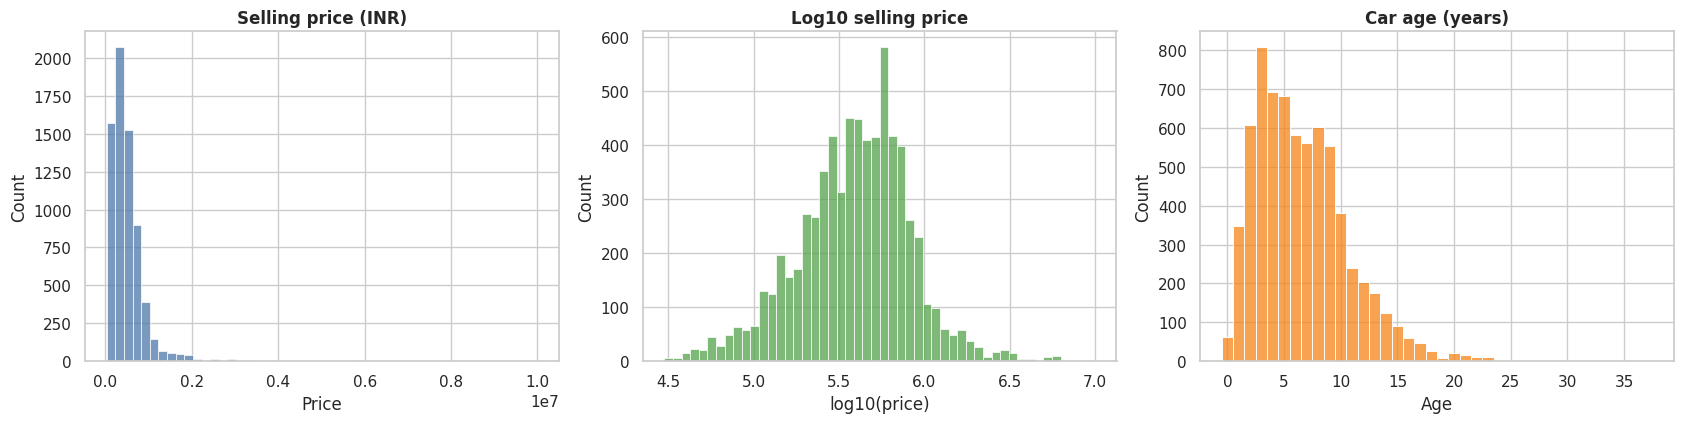

,selling_price,age,km_driven
count,6923.0,6923.0,6923.0
mean,517313.0,7.0,73470.0
std,519866.0,4.0,48549.0
min,29999.0,0.0,1000.0
25%,250000.0,3.0,40000.0
50%,400000.0,6.0,70000.0
75%,634500.0,9.0,100000.0
max,10000000.0,37.0,577414.0


Skewness of price: 5.57; of log price: -0.16


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
sns.histplot(df['selling_price'], bins=50, color='#4C78A8', ax=axes[0])
axes[0].set(title='Selling price (INR)', xlabel='Price')
sns.histplot(np.log10(df['selling_price']), bins=50, color='#54A24B', ax=axes[1])
axes[1].set(title='Log10 selling price', xlabel='log10(price)')
sns.histplot(df['age'], bins=np.arange(-.5, df['age'].max() + 1.5, 1), color='#F58518', ax=axes[2])
axes[2].set(title='Car age (years)', xlabel='Age')
plt.tight_layout()
save_fig(fig, 'q1_distributions.png')
plt.show()
display(df[['selling_price', 'age', 'km_driven']].describe().round(0))
print(f"Skewness of price: {df['selling_price'].skew():.2f}; of log price: {df['ln_price'].skew():.2f}")

**What the code does:** `sns.histplot` draws a histogram, `describe()` summarises each column (count, mean, quartiles) and `skew()` measures asymmetry (0 is symmetric).

**Reading it:** Price is heavily right-skewed (median 400,000, mean 517,313, a few cars at 5 million and above, maximum 10,000,000; skewness 5.6). The log transform makes it almost symmetric (skewness −0.16), which is why the regressions use **log price**: a handful of luxury cars no longer dominate the fit. The typical listing is 6 years old with 70,000 km on the clock.

### Q2. How does price decay as a car gets older?

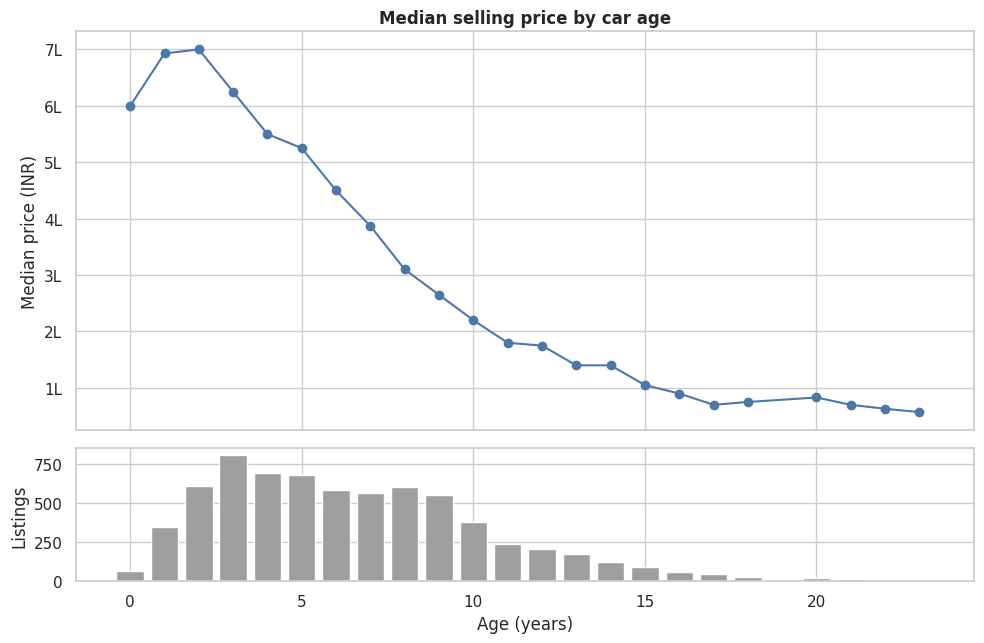

age,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,20,21,22,23
listings,63.0,347.0,608.0,808.0,693.0,681.0,581.0,562.0,603.0,553.0,380.0,240.0,205.0,175.0,123.0,91.0,60.0,47.0,26.0,20.0,17.0,10.0,11.0
median_price,600000.0,693000.0,700000.0,625000.0,550000.0,525000.0,450000.0,387000.0,310000.0,265000.0,220000.0,180000.0,175000.0,140000.0,140000.0,105000.0,90000.0,70000.0,75000.0,83000.0,70000.0,63000.0,57000.0


In [9]:
age_price = df.groupby('age')['selling_price'].agg(listings='size', median_price='median').reset_index()
age_price = age_price[age_price['listings'] >= 10]
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 6.6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax.plot(age_price['age'], age_price['median_price'], marker='o', color='#4C78A8')
ax.set(title='Median selling price by car age', ylabel='Median price (INR)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v / 1e5:.0f}L'))
ax2.bar(age_price['age'], age_price['listings'], color='#9E9E9E')
ax2.set(xlabel='Age (years)', ylabel='Listings')
plt.tight_layout()
save_fig(fig, 'q2_price_by_age.png')
plt.show()
display(age_price.set_index('age').T.round(0))

**What the code does:** `groupby('age').agg(...)` computes the listing count and median price for each age; ages with fewer than 10 listings are left out. The lower panel shows how many cars each point rests on. (The vertical axis is in lakhs, 1L = 100,000 INR.)

**Reading it:** From age 3 the median falls steadily, from 625,000 to 105,000 at age 15 (about 14% a year on average, with noisy year-to-year steps). The first three points do not follow the pattern: age 0 (600,000) sits below ages 1 and 2 (about 700,000). That cohort is small (63 cars) and a different mix of models, a reminder that medians across different cars are not the tracked value of one car. The curved shape hints at a percentage-per-year decay, which Q3 tests.

### Q3. Is depreciation linear or exponential?

Fit both `price ~ age` (linear: a fixed rupee amount per year) and `log(price) ~ age` (exponential: a fixed percentage per year) and compare how much of the variation each explains.

Linear   (price ~ age)      R-squared: 0.188
Log      (log price ~ age)  R-squared: 0.517
Average depreciation: 12.6% per year (95% CI 12.3% to 12.9%)


age,0–1,2–3,4–6,7–9,10–12,13+
listings,410.00,1416.000,1955.000,1718.0,825.000,599.000
mean_residual,-0.11,0.002,0.054,0.0,-0.058,-0.029


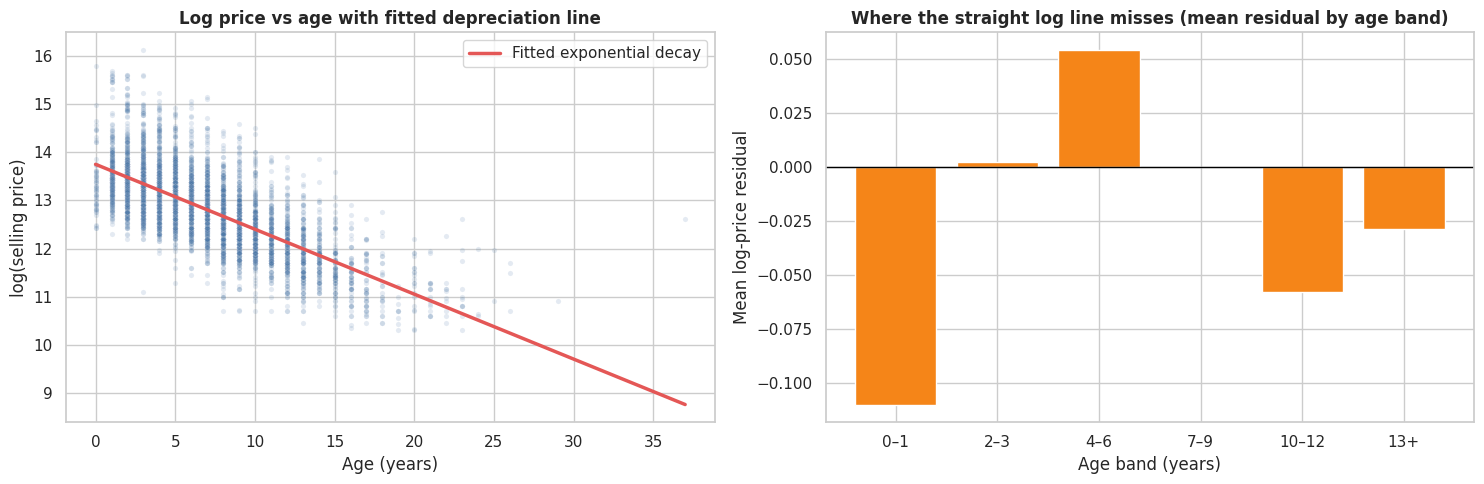

In [10]:
model_log = smf.ols('ln_price ~ age', df).fit()
model_lin = smf.ols('selling_price ~ age', df).fit()
coef = model_log.params['age']
ci_low, ci_high = model_log.conf_int().loc['age']
print(f'Linear   (price ~ age)      R-squared: {model_lin.rsquared:.3f}')
print(f'Log      (log price ~ age)  R-squared: {model_log.rsquared:.3f}')
print(f'Average depreciation: {100 * (1 - np.exp(coef)):.1f}% per year '
      f'(95% CI {100 * (1 - np.exp(ci_high)):.1f}% to {100 * (1 - np.exp(ci_low)):.1f}%)')

df['resid_age_only'] = model_log.resid
bands = pd.cut(df['age'], [-1, 1, 3, 6, 9, 12, 40], labels=['0–1', '2–3', '4–6', '7–9', '10–12', '13+'])
resid_by_band = df.groupby(bands, observed=True)['resid_age_only'].agg(listings='size', mean_residual='mean').round(3)
display(resid_by_band.T)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(x=df['age'], y=df['ln_price'], alpha=.15, s=14, color='#4C78A8', ax=axes[0])
grid = np.arange(0, df['age'].max() + 1)
axes[0].plot(grid, model_log.params['Intercept'] + coef * grid, color='#E45756', linewidth=2.5, label='Fitted exponential decay')
axes[0].set(title='Log price vs age with fitted depreciation line', xlabel='Age (years)', ylabel='log(selling price)')
axes[0].legend()
axes[1].bar(resid_by_band.index.astype(str), resid_by_band['mean_residual'], color='#F58518')
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set(title='Where the straight log line misses (mean residual by age band)',
            xlabel='Age band (years)', ylabel='Mean log-price residual')
plt.tight_layout()
save_fig(fig, 'q3_depreciation_fit.png')
plt.show()

**What the code does:** `smf.ols('y ~ x', data).fit()` fits an ordinary least squares regression, `.rsquared` reports the share of variation explained, and `conf_int()` gives the 95% confidence interval. Because the model is on log price, `1 − exp(coefficient)` converts the age coefficient into a yearly percentage loss. A residual is the gap between the actual and the fitted log price.

**Reading it:** The exponential model explains **52%** of the variation in price against **19%** for the straight line, so depreciation is much closer to a fixed percentage than a fixed rupee amount. The average loss is **12.6% a year** (95% CI 12.3–12.9%). The right panel shows the limit of "constant": cars aged 0–1 sit 11% below the line on average and cars aged 4–6 about 5% above it, so the first years are flatter than the rest. This is an association across different cars, not the tracked value of one car.

### Q4. Which brands retain value best? (Value Retention Score)

**Our first original feature.** A brand's average price mostly reflects what kind of cars it sells, not how fast they lose value. So the score is built from each brand's **own** depreciation rate: for every brand with 100+ listings, regress log price on age while holding power and kilometres constant. The age coefficient gives the **Value Retention Score: the percentage of its value a brand's car keeps for each extra year of age.** Brands with too few listings (all the luxury brands) are not scored.

,brand,listings,age_span_years,retention_score,ci_low,ci_high,median_price
0,Renault,206,8,93.9,91.7,96.2,395000.0
1,Volkswagen,172,12,91.8,89.8,93.8,418000.0
2,Ford,353,17,90.2,89.2,91.2,450000.0
3,Mahindra,708,17,90.0,89.3,90.8,570000.0
4,Maruti,2088,26,89.7,89.2,90.1,350500.0
5,Tata,633,20,88.6,87.8,89.4,265000.0
6,Honda,360,18,87.6,86.7,88.6,560000.0
7,Toyota,324,18,87.5,86.1,89.0,750000.0
8,Hyundai,1213,18,87.3,86.8,87.8,425000.0
9,Chevrolet,216,12,85.6,83.8,87.4,220000.0


Naive "age-adjusted price" ranking (top 5): BMW, Mercedes-Benz, Audi, Toyota, Mahindra


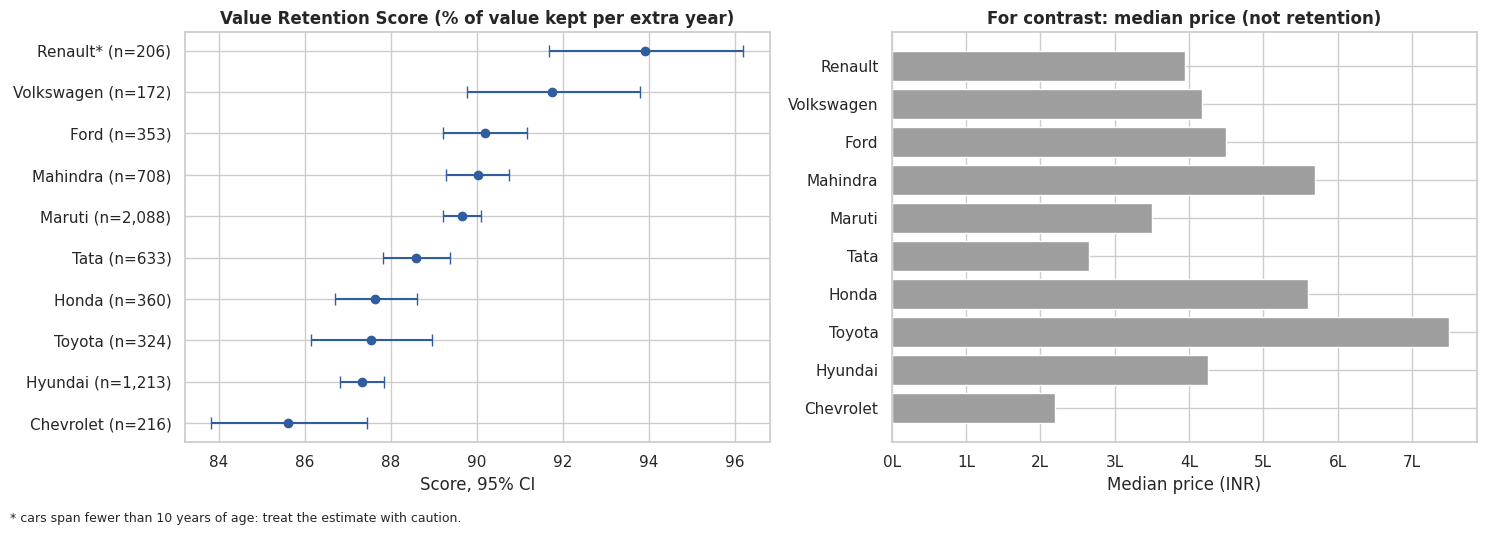

In [11]:
rows = []
for brand, g in cm.groupby('brand'):
    if len(g) < 100:
        continue
    fit = smf.ols('ln_price ~ age + ln_power + ln_km', g).fit(cov_type='HC3')
    lo, hi = fit.conf_int().loc['age']
    rows.append({'brand': brand, 'listings': len(g), 'age_span_years': int(g['age'].max() - g['age'].min()),
                 'retention_score': 100 * np.exp(fit.params['age']),
                 'ci_low': 100 * np.exp(lo), 'ci_high': 100 * np.exp(hi),
                 'median_price': g['selling_price'].median()})
vrs = pd.DataFrame(rows).sort_values('retention_score', ascending=False).reset_index(drop=True)
display(vrs.round(1))

# Why not just rank by age-adjusted price? Compare with the naive version.
naive = (cm.assign(naive_resid=smf.ols('ln_price ~ age', cm).fit().resid)
           .groupby('brand')['naive_resid'].agg(['mean', 'size']))
naive = naive[naive['size'] >= 30].sort_values('mean', ascending=False)
print('Naive "age-adjusted price" ranking (top 5):', ', '.join(naive.index[:5]))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
plot = vrs.iloc[::-1]
axes[0].errorbar(plot['retention_score'], range(len(plot)),
                 xerr=[plot['retention_score'] - plot['ci_low'], plot['ci_high'] - plot['retention_score']],
                 fmt='o', color='#2F5D9E', capsize=4)
axes[0].set_yticks(range(len(plot)))
axes[0].set_yticklabels([f"{b}{'*' if s < 10 else ''} (n={n:,})" for b, s, n in zip(plot['brand'], plot['age_span_years'], plot['listings'])])
axes[0].set(title='Value Retention Score (% of value kept per extra year)', xlabel='Score, 95% CI')
axes[1].barh(range(len(plot)), plot['median_price'], color='#9E9E9E')
axes[1].set_yticks(range(len(plot)))
axes[1].set_yticklabels(plot['brand'])
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v / 1e5:.0f}L'))
axes[1].set(title='For contrast: median price (not retention)', xlabel='Median price (INR)')
fig.text(.01, -.02, '* cars span fewer than 10 years of age: treat the estimate with caution.', fontsize=9)
plt.tight_layout()
save_fig(fig, 'q4_value_retention_score.png')
plt.show()

**What the code does:** the loop fits one regression per brand (`cov_type='HC3'` gives standard errors that stay valid when variance differs across cars). `100 × exp(age coefficient)` converts the log slope into "percent of value kept per year". The naive version, the average gap from one pooled age line, is computed to show why it is the wrong measure.

**Reading it:** Holding power and kilometres constant, brands keep **about 86–92% of their value per extra year** (Renault, flagged below, is the exception at 94%). Volkswagen (91.8%), Ford (90.2%), Mahindra (90.0%) and Maruti (89.7%) lose value most slowly among the well-sampled brands; Hyundai (87.3%), Toyota (87.5%), Honda (87.6%) and especially Chevrolet (85.6%) lose it fastest. The spread is modest and several intervals overlap, so only the ends of the ranking are firm. Renault (93.9%) is flagged: its cars span only 0–8 years, so the estimate leans on a short, model-mix-dependent range.

**Why this score is different:** the naive "age-adjusted price" ranking puts the luxury brands first, because BMW, Mercedes and Audi are expensive at any age, and says nothing about how fast they lose value. The right panel shows how price level and retention are different things: Toyota is the most expensive of the scored brands but depreciates faster than Maruti.

### Q5. Is there a diesel price premium, and how big is it?

Compare diesel and petrol cars on **log price** with a Welch t-test (which does not assume equal variances), so the result reads as a percentage difference.

Diesel (n=3,754) vs petrol (n=3,076): 72.1% higher on average (95% CI 66.3% to 78.1%), Welch t = 31.1
Median age: {'CNG': 4.0, 'Diesel': 6.0, 'LPG': 10.0, 'Petrol': 6.0} | median power (bhp): {'CNG': 60.015, 'Diesel': 88.73, 'LPG': 58.2, 'Petrol': 78.9}


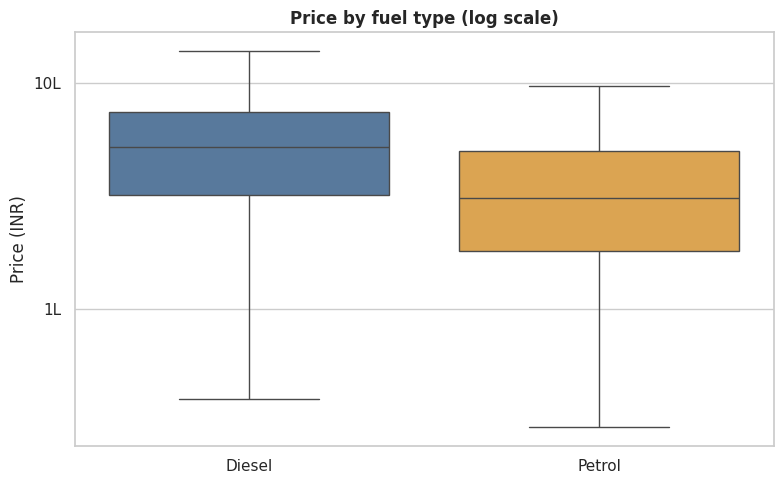

In [12]:
diesel = df.loc[df['fuel'] == 'Diesel', 'ln_price']
petrol = df.loc[df['fuel'] == 'Petrol', 'ln_price']
t, p = stats.ttest_ind(diesel, petrol, equal_var=False)
diff = diesel.mean() - petrol.mean()
se = np.sqrt(diesel.var() / len(diesel) + petrol.var() / len(petrol))
pct = lambda x: 100 * (np.exp(x) - 1)
print(f'Diesel (n={len(diesel):,}) vs petrol (n={len(petrol):,}): {pct(diff):.1f}% higher on average '
      f'(95% CI {pct(diff - 1.96 * se):.1f}% to {pct(diff + 1.96 * se):.1f}%), Welch t = {t:.1f}')
print('Median age:', df.groupby('fuel')['age'].median().to_dict(), '| median power (bhp):',
      df.groupby('fuel')['power_bhp'].median().to_dict())

fig, ax = plt.subplots(figsize=(8, 5))
plot_df = df[df['fuel'].isin(['Diesel', 'Petrol'])]
sns.boxplot(data=plot_df, x='fuel', y='selling_price', showfliers=False, palette=['#4C78A8', '#F2A93B'], ax=ax)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v / 1e5:g}L'))
ax.set(title='Price by fuel type (log scale)', xlabel='', ylabel='Price (INR)')
plt.tight_layout()
save_fig(fig, 'q5_diesel_premium.png')
plt.show()

**What the code does:** `ttest_ind(..., equal_var=False)` is the Welch test, `np.exp(difference) − 1` turns a log-price difference into a percentage, and `1.96 × standard error` builds the 95% interval. `showfliers=False` hides extreme dots in the boxplot, and a log axis keeps cheap and expensive cars readable on one scale.

**Reading it:** Diesels sell for **72% more** than petrol cars on raw averages (95% CI 66–78%; n = 3,754 and 3,076). With samples this large the test is overwhelmingly "significant", so what matters is the size and what it hides: diesels are also bigger and more powerful cars. **Q9 controls for that and finds the premium falls to about 27%.**

### Q6. How much does each extra previous owner cost?

,listings,median_price,median_age
owner,,,
First Owner,4241,500000.0,4.0
Second Owner,1973,305000.0,8.0
Third Owner,536,222500.0,10.0
Fourth & Above Owner,168,170000.0,12.0


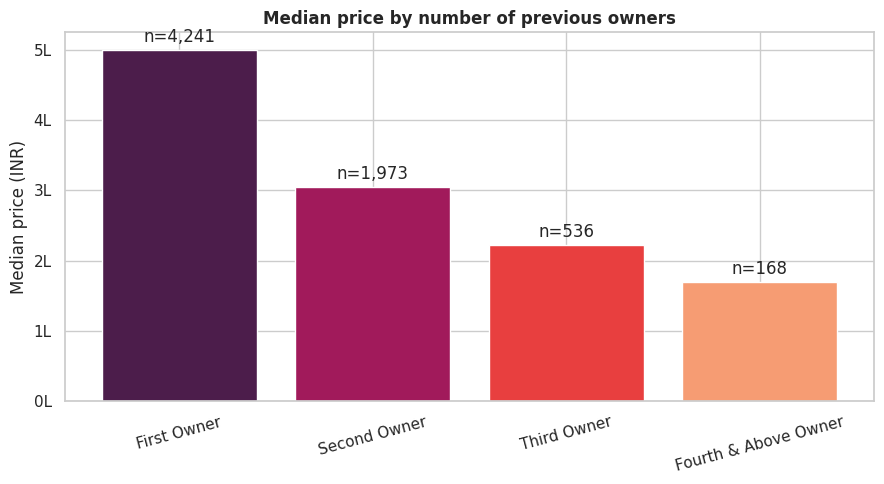

In [13]:
owner_stats = (df[df['owner'].isin(owner_levels)].groupby('owner').agg(listings=('selling_price', 'size'), median_price=('selling_price', 'median'),
                                       median_age=('age', 'median')).reindex(owner_levels))
display(owner_stats)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(owner_stats.index, owner_stats['median_price'], color=sns.color_palette('rocket', 4))
ax.bar_label(bars, labels=[f"n={n:,}" for n in owner_stats['listings']], padding=3)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v / 1e5:.0f}L'))
ax.set(title='Median price by number of previous owners', ylabel='Median price (INR)', xlabel='')
plt.xticks(rotation=15)
plt.tight_layout()
save_fig(fig, 'q6_price_by_owner.png')
plt.show()

**What the code does:** `groupby('owner').agg(...)` gives each owner group's listing count, median price and median age, and `reindex` puts the groups in order. `bar_label` writes the group size on each bar.

**Reading it:** The median price drops from 500,000 (first owner) to 305,000, 222,500 and 170,000 for second, third and fourth-plus owners. But the cars also get older at each step (median age 4, 8, 10 and 12 years), so this raw gap mixes owner count with age. **Q9 isolates the owner effect: about −8%, −12% and −14% versus a first owner.**

### Q7. Does transmission affect resale price?

,listings,median_price,median_age,median_power_bhp
transmission,,,,
Automatic,584,850000.0,4.0,126.2
Manual,6339,385000.0,6.0,81.8


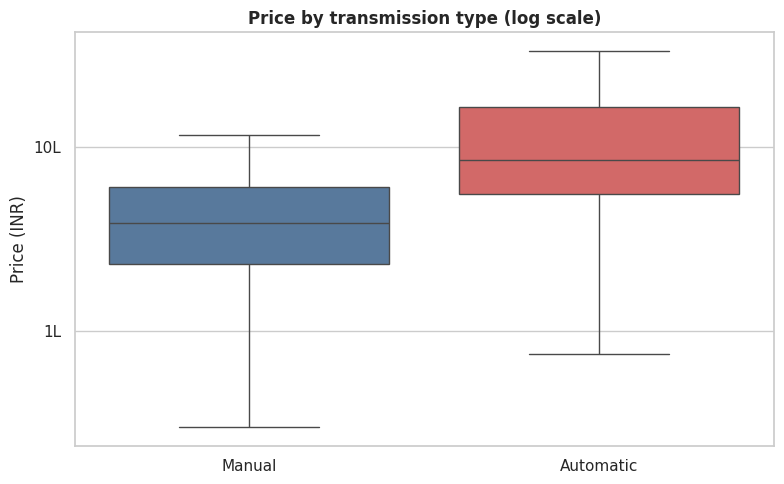

In [14]:
trans_stats = df.groupby('transmission').agg(listings=('selling_price', 'size'), median_price=('selling_price', 'median'),
                                            median_age=('age', 'median'), median_power_bhp=('power_bhp', 'median'))
display(trans_stats)
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x='transmission', y='selling_price', showfliers=False, palette=['#4C78A8', '#E45756'], ax=ax)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v / 1e5:g}L'))
ax.set(title='Price by transmission type (log scale)', xlabel='', ylabel='Price (INR)')
plt.tight_layout()
save_fig(fig, 'q7_price_by_transmission.png')
plt.show()

**Reading it:** Automatics have a median price of 850,000 against 385,000 for manuals, but they are also newer (median age 4 vs 6 years) and far more powerful (126 vs 82 bhp), and only 584 of the 6,923 listings are automatic. The raw gap is mostly a different kind of car. **Q9 puts the like-for-like automatic premium at about 18%.**

### Q8. How much does mileage reduce price, independent of age?

Kilometres and age move together (correlation about 0.5), and high-mileage cars are also a different kind of car. The effect of doubling the kilometres is estimated under four sets of controls to see how much the answer depends on them.

,controls,effect_of_doubling_km_%,ci_low,ci_high
0,No controls,-16.4,-17.5,-15.2
1,Control for age,7.9,6.5,9.3
2,Control for age and car type,-4.0,-4.9,-3.2
3,Full model (Q9),-3.9,-4.6,-3.1


Share of diesel cars by km driven:
{'up to 50k': 0.35, '50k–100k': 0.6, '100k–150k': 0.77, 'over 150k': 0.88}


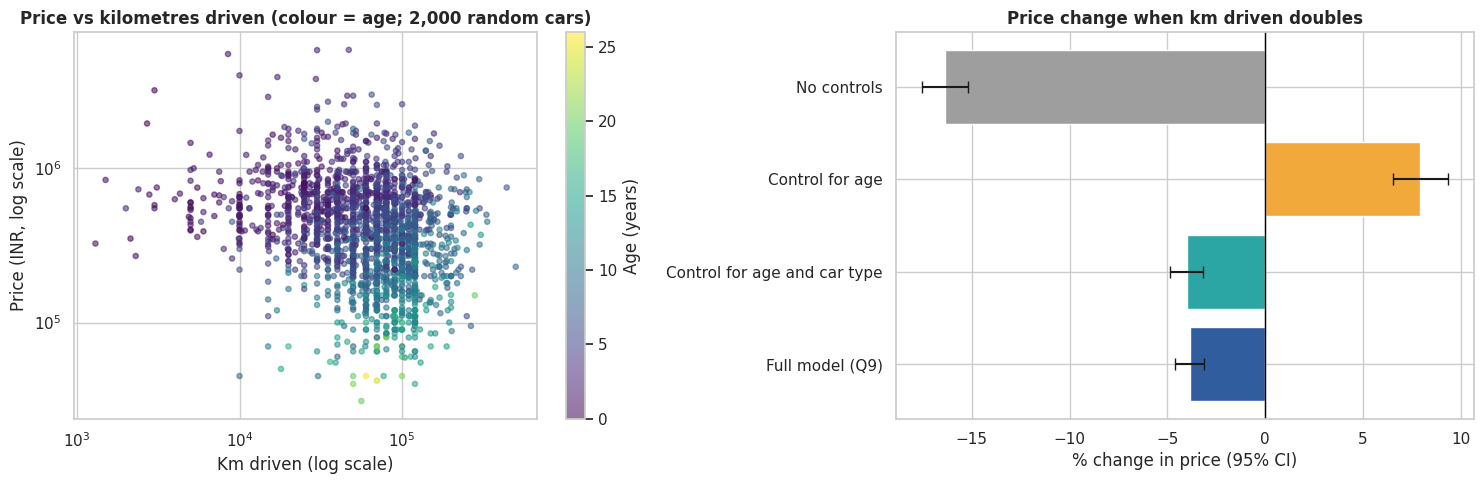

In [15]:
specs = {
    'No controls': 'ln_price ~ ln_km',
    'Control for age': 'ln_price ~ age + ln_km',
    'Control for age and car type': 'ln_price ~ age + ln_km + ln_power + I(engine_cc / 100) + C(fuel) + C(transmission)',
    'Full model (Q9)': ('ln_price ~ age + ln_km + ln_power + I(engine_cc / 100) + C(fuel) + C(transmission)'
                        ' + C(owner) + C(seller_type) + C(brand_group)'),
}
rows = []
for label, formula in specs.items():
    fit = smf.ols(formula, cm).fit(cov_type='HC3')
    lo, hi = fit.conf_int().loc['ln_km']
    eff = lambda c: 100 * (np.exp(c * np.log(2)) - 1)
    rows.append({'controls': label, 'effect_of_doubling_km_%': eff(fit.params['ln_km']), 'ci_low': eff(lo), 'ci_high': eff(hi)})
km_effect = pd.DataFrame(rows)
display(km_effect.round(1))
print('Share of diesel cars by km driven:')
print((cm.groupby(pd.cut(cm['km_driven'], [0, 50_000, 100_000, 150_000, 10 ** 7],
                         labels=['up to 50k', '50k–100k', '100k–150k', 'over 150k']), observed=True)['fuel']
         .apply(lambda s: (s == 'Diesel').mean()).round(2).to_dict()))

sample = cm.sample(2000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sc = axes[0].scatter(sample['km_driven'], sample['selling_price'], c=sample['age'], cmap='viridis', alpha=.55, s=14)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set(title='Price vs kilometres driven (colour = age; 2,000 random cars)', xlabel='Km driven (log scale)',
            ylabel='Price (INR, log scale)')
plt.colorbar(sc, ax=axes[0], label='Age (years)')
y = km_effect['effect_of_doubling_km_%']
axes[1].barh(range(4), y, xerr=[y - km_effect['ci_low'], km_effect['ci_high'] - y], color=['#9E9E9E', '#F2A93B', '#2CA6A4', '#2F5D9E'], capsize=4)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_yticks(range(4)); axes[1].set_yticklabels(km_effect['controls']); axes[1].invert_yaxis()
axes[1].set(title='Price change when km driven doubles', xlabel='% change in price (95% CI)')
plt.tight_layout()
save_fig(fig, 'q8_price_vs_km.png')
plt.show()

**What the code does:** each formula is an OLS regression of log price; `ln_km` is the log of kilometres, so its coefficient converts into the percentage change in price when kilometres double (`exp(coef × ln 2) − 1`). `C(fuel)` tells the formula that fuel is a category, and `I(engine_cc / 100)` rescales engine size to 100 cc units. The loop repeats the same estimate with progressively more controls.

**Reading it:** The answer **flips sign** depending on the controls. With no controls, doubling the kilometres goes with a **16% lower** price. Holding age fixed it goes with a **7.9% higher** price, the opposite sign, because among cars of the same age the high-mileage ones are mostly diesels (35% of cars under 50,000 km are diesel against 88% of those over 150,000 km), which cost more. Once car type is controlled (and in the full model), doubling the kilometres goes with an about **4% lower** price (4.0% and 3.9%). Kilometres matter, but far less than age; this is a good example of why a raw relationship should not be read as an effect.

### Q9. What factors move price most? (multiple regression)

One regression of **log price** on age, kilometres, power, engine size, fuel, transmission, owners, seller type and brand. Each coefficient is the effect of that factor **holding the others constant**, converted to a percentage. Because continuous factors are in different units, they are shown as the effect of moving from the 25th to the 75th percentile (the interquartile range), so the bars are comparable. Standard errors are robust (HC3).

R-squared: 0.884  |  observations: 6,709


,effect_%,ci_low_%,ci_high_%
factor,,,
Age: +6 years (25th to 75th pct),-47.0,-47.9,-46.0
Kilometres: 25th to 75th percentile,-5.3,-6.4,-4.3
Power: 25th to 75th percentile,39.4,37.6,41.3
Engine: 25th to 75th percentile,8.8,7.9,9.7
Diesel vs petrol,26.9,24.8,29.0
CNG vs petrol,-6.1,-11.0,-1.0
LPG vs petrol,15.1,5.6,25.5
Automatic vs manual,17.5,14.4,20.7
Second owner vs first,-7.8,-9.3,-6.4


Diesel vs petrol: 70.2% raw  ->  26.9% in the full model


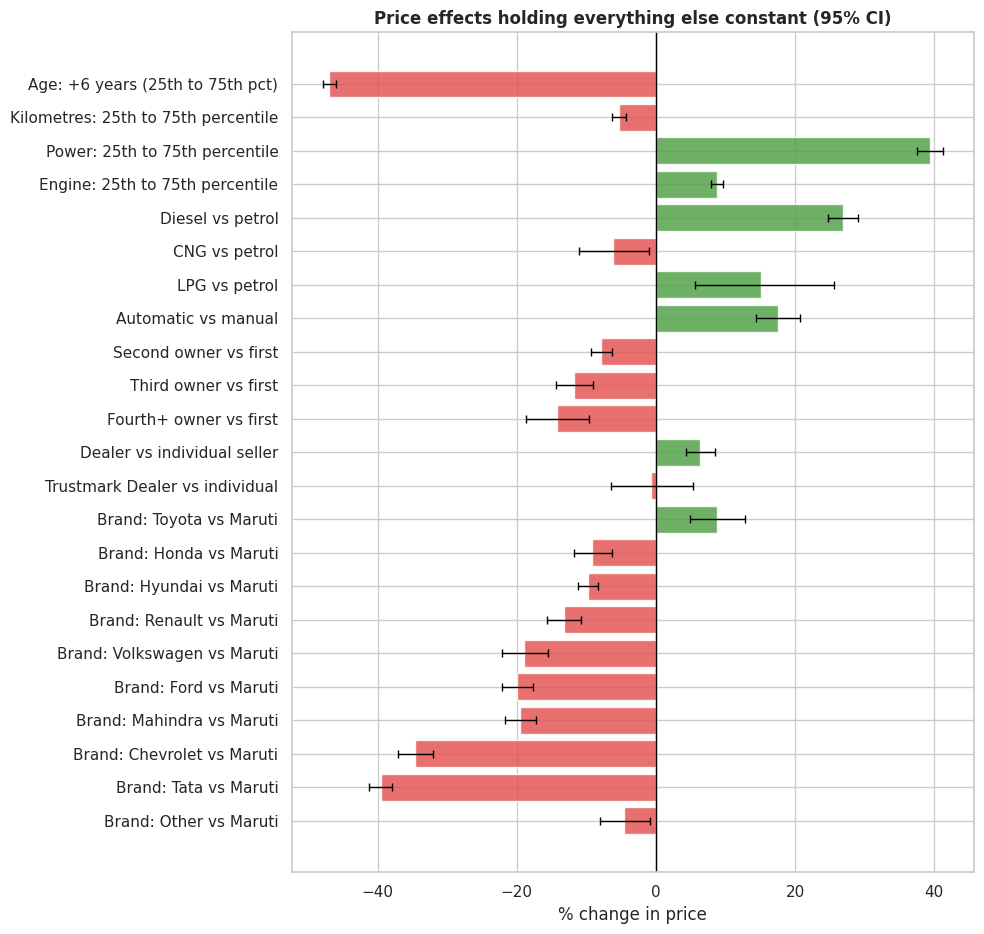

In [16]:
formula = ("ln_price ~ age + ln_km + ln_power + I(engine_cc / 100) + C(fuel, Treatment('Petrol'))"
           " + C(transmission, Treatment('Manual')) + C(owner, Treatment('First Owner'))"
           " + C(seller_type, Treatment('Individual')) + C(brand_group, Treatment('Maruti'))")
full = smf.ols(formula, cm).fit(cov_type='HC3')
ci = full.conf_int()
print(f'R-squared: {full.rsquared:.3f}  |  observations: {int(full.nobs):,}')


def pct_effect(name, scale=1.0):
    # percent change in price for a change of `scale` units of the variable (or a category contrast)
    return [100 * (np.exp(v * scale) - 1) for v in (full.params[name], ci.loc[name, 0], ci.loc[name, 1])]


def cat(var, ref, level):
    return f"C({var}, Treatment('{ref}'))[T.{level}]"


iqr = lambda col: cm[col].quantile(.75) - cm[col].quantile(.25)
effects = [
    (f"Age: +{iqr('age'):.0f} years (25th to 75th pct)", pct_effect('age', iqr('age'))),
    ('Kilometres: 25th to 75th percentile', pct_effect('ln_km', iqr('ln_km'))),
    ('Power: 25th to 75th percentile', pct_effect('ln_power', iqr('ln_power'))),
    ('Engine: 25th to 75th percentile', pct_effect('I(engine_cc / 100)', iqr('engine_cc') / 100)),
    ('Diesel vs petrol', pct_effect(cat('fuel', 'Petrol', 'Diesel'))),
    ('CNG vs petrol', pct_effect(cat('fuel', 'Petrol', 'CNG'))),
    ('LPG vs petrol', pct_effect(cat('fuel', 'Petrol', 'LPG'))),
    ('Automatic vs manual', pct_effect(cat('transmission', 'Manual', 'Automatic'))),
    ('Second owner vs first', pct_effect(cat('owner', 'First Owner', 'Second Owner'))),
    ('Third owner vs first', pct_effect(cat('owner', 'First Owner', 'Third Owner'))),
    ('Fourth+ owner vs first', pct_effect(cat('owner', 'First Owner', 'Fourth & Above Owner'))),
    ('Dealer vs individual seller', pct_effect(cat('seller_type', 'Individual', 'Dealer'))),
    ('Trustmark Dealer vs individual', pct_effect(cat('seller_type', 'Individual', 'Trustmark Dealer'))),
]
for b in ['Toyota', 'Honda', 'Hyundai', 'Renault', 'Volkswagen', 'Ford', 'Mahindra', 'Chevrolet', 'Tata', 'Other']:
    effects.append((f'Brand: {b} vs Maruti', pct_effect(cat('brand_group', 'Maruti', b))))
table = pd.DataFrame([{'factor': k, 'effect_%': v[0], 'ci_low_%': v[1], 'ci_high_%': v[2]} for k, v in effects]).set_index('factor')
display(table.round(1))

crude_diesel = smf.ols("ln_price ~ C(fuel, Treatment('Petrol'))", cm).fit()
print(f"Diesel vs petrol: {100 * (np.exp(crude_diesel.params[cat('fuel', 'Petrol', 'Diesel')]) - 1):.1f}% raw  ->  "
      f"{table.loc['Diesel vs petrol', 'effect_%']:.1f}% in the full model")

fig, ax = plt.subplots(figsize=(10, 9.5))
plot = table.iloc[::-1]
colors = ['#E45756' if v < 0 else '#54A24B' for v in plot['effect_%']]
ax.barh(range(len(plot)), plot['effect_%'], color=colors, alpha=.85)
ax.errorbar(plot['effect_%'], range(len(plot)), xerr=[plot['effect_%'] - plot['ci_low_%'], plot['ci_high_%'] - plot['effect_%']],
            fmt='none', ecolor='black', capsize=3, linewidth=1)
ax.axvline(0, color='black', linewidth=1)
ax.set_yticks(range(len(plot))); ax.set_yticklabels(plot.index)
ax.set(title='Price effects holding everything else constant (95% CI)', xlabel='% change in price')
plt.tight_layout()
save_fig(fig, 'q9_price_drivers.png')
plt.show()

**What the code does:** the formula uses `Treatment('Petrol')` and similar terms to **set the reference group for each category explicitly**, so every categorical effect reads "versus petrol", "versus manual" and so on. `pct_effect` converts a log coefficient into a percentage change; for continuous variables it multiplies the coefficient by the interquartile range so the factors share a scale. `cov_type='HC3'` gives robust standard errors.

**Reading it (associations, not causes):**

- **Age is the dominant factor:** a car 9 years old instead of 3 is about **47% cheaper** at the same mileage, power and so on. **Power** comes next (the 25th to 75th percentile, 67 to 100 bhp, is worth about **+39%**), then **brand**: against Maruti, Tata is about 40% cheaper and Chevrolet 35% cheaper, while Toyota is about 9% dearer.
- **Kilometres are minor** once everything else is held constant (the interquartile range is worth about −5%).
- **Diesel premium:** 70% raw falls to about **27%** (95% CI 25–29%) after the controls, so most of the raw premium was the car, but a real premium remains. CNG is about 6% below petrol and LPG about 15% above, from only 51 and 35 cars.
- **Automatics** carry about **+18%** like-for-like (95% CI 14–21%), and each extra owner costs about **8%, 12% and 14%** (second, third, fourth-plus) against a first owner. Dealers list about 6% higher than individuals; Trustmark Dealer (27 cars) is not distinguishable from zero.
- The model explains **88%** of the variation in log price.

### Q10. Which listings look like the best bargains? (Deal Score)

**Our second original feature.** A *fair-price model* predicts what each car should cost; a car asking well **below** that has a positive Deal Score (bargain), one asking above has a negative score (overpriced). Three candidate models are compared with 5-fold cross-validation, and every listing is scored by a model that **never saw that listing**, so the score is not a fit to its own price. The best model is used.

,cv_r2_log_price,median_abs_error_%,p75_abs_error_%
model,,,
Linear regression (specs + brand),0.883,15.612,26.864
Ridge regression (+ model name),0.917,12.136,21.429
Gradient boosting (+ model name),0.924,10.901,19.745


Model used for the Deal Score: Gradient boosting (+ model name)

Lists below use the 6,009 listings whose model has 20+ comparable listings.
Top 10 apparent bargains (asking price well below fair price):


,name,year,km_driven,selling_price,fair_price,deal_score
6631,Tata Safari DICOR 2.2 LX 4x2,2012,82507,132000,437395.0,70.0
4174,Maruti Wagon R VXI,2004,90000,33351,101987.0,67.0
6338,Ford Fiesta 1.4 ZXi TDCi Limited Edition,2006,201000,55000,164182.0,66.0
6117,Tata New Safari 4X4 EXI BSIII,2007,120000,95000,263037.0,64.0
6623,Tata Manza Aqua Quadrajet,2011,97343,88000,239726.0,63.0
1953,Maruti Zen LXI,2001,10000,30000,81508.0,63.0
2570,Tata Indica V2 LSi,2012,12000,75000,200291.0,63.0
5747,Volkswagen Polo 1.5 TDI Comfortline,2020,50000,260000,683040.0,62.0
2215,Maruti Baleno LXI,2005,90000,50000,130080.0,62.0
5203,Maruti Swift VDI Deca,2016,210000,210000,535243.0,61.0


Top 10 apparently overpriced listings:


,name,year,km_driven,selling_price,fair_price,deal_score
5715,Mahindra Xylo E8 ABS Airbag,2011,230000,600000,209587.0,-186.0
3743,Tata Indigo TDI,2010,100000,409999,147570.0,-178.0
5437,Maruti Zen VXI,2003,121000,200000,72228.0,-177.0
1297,Maruti 800 AC BSIII,2002,120000,120000,44092.0,-172.0
4692,Toyota Innova 2.5 G4 Diesel 7-seater,2006,250000,1050000,420474.0,-150.0
3403,Tata New Safari DICOR 2.2 VX 4x2,2012,90000,725000,299859.0,-142.0
6261,Maruti 800 AC,2006,70000,155000,65835.0,-135.0
2098,Maruti Wagon R VXI,2006,70000,250000,107833.0,-132.0
5852,Tata Indigo CS GLX BS III,2008,100000,250000,108729.0,-130.0
1786,Honda City 1.5 GXI,2004,110000,198000,87650.0,-126.0


Typical model error: 10.9% (median). Share of listings with |score| above 25: 16.9%


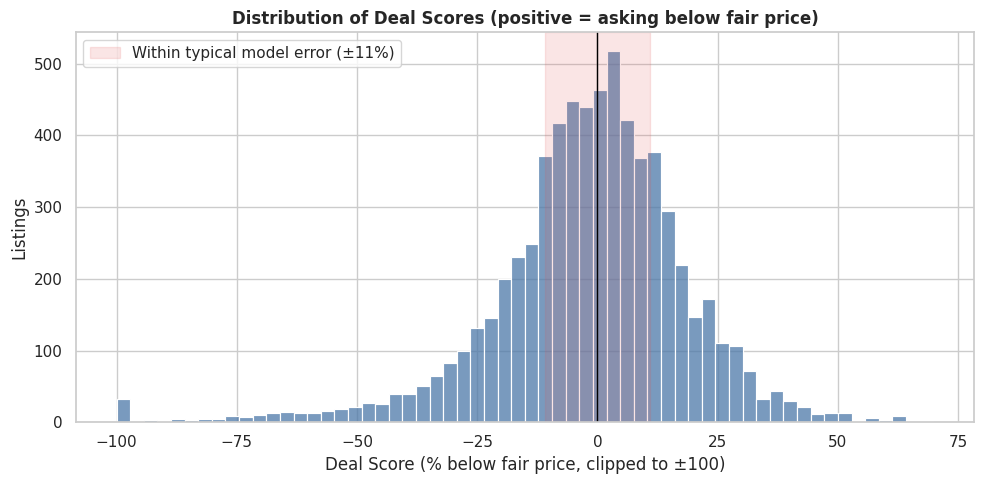

In [17]:
cat_cols = ['fuel', 'transmission', 'owner', 'seller_type', 'brand_group']
num_cols = ['age', 'ln_km', 'power_bhp', 'engine_cc']
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_ln = cm['ln_price']


def one_hot_pipeline(cats, estimator):
    pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cats), ('num', StandardScaler(), num_cols)])
    return make_pipeline(pre, estimator)


boosted_cats = cat_cols + ['model']
candidates = {
    'Linear regression (specs + brand)': (cat_cols, one_hot_pipeline(cat_cols, LinearRegression())),
    'Ridge regression (+ model name)': (boosted_cats, one_hot_pipeline(boosted_cats, Ridge(alpha=3.0))),
    'Gradient boosting (+ model name)': (boosted_cats, make_pipeline(
        ColumnTransformer([('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), boosted_cats),
                           ('num', 'passthrough', num_cols)]),
        HistGradientBoostingRegressor(categorical_features=list(range(len(boosted_cats))),
                                      learning_rate=.06, max_iter=300, random_state=RANDOM_STATE))),
}
rows, oof = [], {}
for label, (cols, pipe) in candidates.items():
    pred = cross_val_predict(pipe, cm[cols + num_cols], y_ln, cv=cv)
    oof[label] = pred
    err = 100 * np.abs(np.exp(pred) - cm['selling_price']) / cm['selling_price']
    rows.append({'model': label, 'cv_r2_log_price': 1 - ((y_ln - pred) ** 2).sum() / ((y_ln - y_ln.mean()) ** 2).sum(),
                 'median_abs_error_%': err.median(), 'p75_abs_error_%': err.quantile(.75)})
comparison = pd.DataFrame(rows).set_index('model')
display(comparison.round(3))

best = comparison['cv_r2_log_price'].idxmax()
print('Model used for the Deal Score:', best)
cm['fair_price'] = np.exp(oof[best])
cm['deal_score'] = ((cm['fair_price'] - cm['selling_price']) / cm['fair_price'] * 100).round(1)
typical_error = comparison.loc[best, 'median_abs_error_%']

show_cols = ['name', 'year', 'km_driven', 'selling_price', 'fair_price', 'deal_score']
eligible = cm[cm['model_listings'] >= 20]
print(f'\nLists below use the {len(eligible):,} listings whose model has 20+ comparable listings.')
print('Top 10 apparent bargains (asking price well below fair price):')
display(eligible.sort_values('deal_score', ascending=False)[show_cols].head(10).round(0))
print('Top 10 apparently overpriced listings:')
display(eligible.sort_values('deal_score')[show_cols].head(10).round(0))
print(f"Typical model error: {typical_error:.1f}% (median). Share of listings with |score| above 25: {(cm['deal_score'].abs() > 25).mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(cm['deal_score'].clip(-100, 100), bins=60, color='#4C78A8', ax=ax)
ax.axvline(0, color='black', linewidth=1)
ax.axvspan(-typical_error, typical_error, color='#E45756', alpha=.15, label=f'Within typical model error (±{typical_error:.0f}%)')
ax.set(title='Distribution of Deal Scores (positive = asking below fair price)',
       xlabel='Deal Score (% below fair price, clipped to ±100)', ylabel='Listings')
ax.legend()
plt.tight_layout()
save_fig(fig, 'q10_deal_score.png')
plt.show()

**What the code does:** `cross_val_predict` splits the data into 5 parts, trains on four and predicts the fifth, so each prediction comes from a model that did not see that car. `OneHotEncoder` turns each category into 0/1 columns, `Ridge` is a regression with a small penalty that keeps coefficients stable when there are many models, and `HistGradientBoostingRegressor` builds many small decision trees that capture interactions. The Deal Score is `(fair price − asking price) / fair price × 100`.

**Reading it:** Adding brand and **model name** matters: the cross-validated R² on log price rises from 0.883 (specs and brand) to 0.917 (ridge with model name) and 0.924 (gradient boosting), and the median pricing error falls from about 16% to 11%. The Deal Score therefore only identifies a listing as a bargain if it is **more than roughly 11% (median error) below fair, and realistically 20% or more**, since a quarter of listings miss by 20% or more. The lists are limited to models with 20+ listings so that "fair" rests on real comparables; rare models (collector cars, a single ultra-luxury listing) cannot be scored fairly. The extreme scores are mostly older cars and listings whose variant, condition or accident history the data cannot see, so treat the score as a **shortlist to inspect in person**, not a guarantee.

### Q11. How confident are we in each brand's average price?

A mean without uncertainty is misleading. Because prices are skewed, the **geometric mean** (the average on the log scale, converted back) is used, with a 95% confidence interval, for the 8 most common brands.

,listings,typical_price,low,high
brand,,,,
Chevrolet,216,224607.0,207422.0,243215.0
Tata,647,259313.0,244522.0,274998.0
Maruti,2164,311525.0,302134.0,321208.0
Hyundai,1266,373634.0,360410.0,387344.0
Ford,361,408342.0,381798.0,436732.0
Honda,362,494379.0,465376.0,525190.0
Mahindra,722,538753.0,517945.0,560397.0
Toyota,357,705984.0,657587.0,757943.0


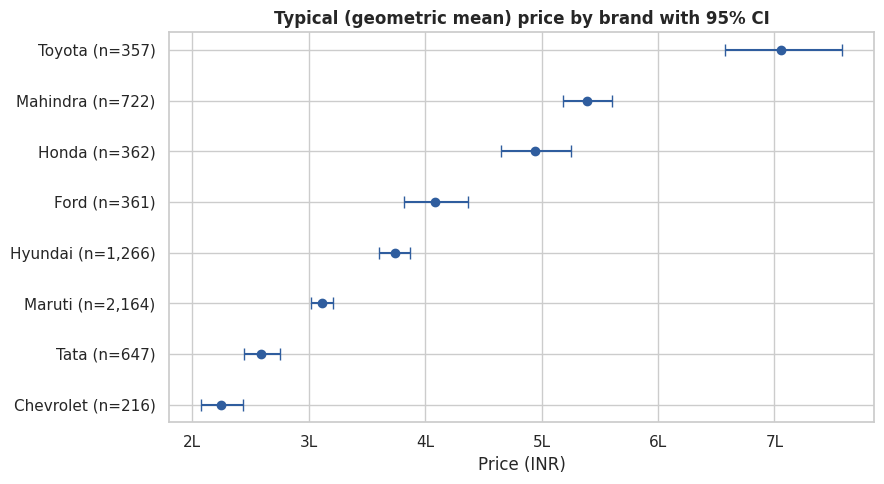

In [18]:
rows = []
for brand in df['brand'].value_counts().head(8).index:
    v = df.loc[df['brand'] == brand, 'ln_price']
    se = v.std(ddof=1) / np.sqrt(len(v))
    rows.append({'brand': brand, 'listings': len(v), 'typical_price': np.exp(v.mean()),
                 'low': np.exp(v.mean() - 1.96 * se), 'high': np.exp(v.mean() + 1.96 * se)})
ci_df = pd.DataFrame(rows).sort_values('typical_price')
display(ci_df.round(0).set_index('brand'))

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(ci_df['typical_price'], range(len(ci_df)),
            xerr=[ci_df['typical_price'] - ci_df['low'], ci_df['high'] - ci_df['typical_price']],
            fmt='o', color='#2F5D9E', capsize=4)
ax.set_yticks(range(len(ci_df)))
ax.set_yticklabels([f"{b} (n={n:,})" for b, n in zip(ci_df['brand'], ci_df['listings'])])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v / 1e5:.0f}L'))
ax.set(title='Typical (geometric mean) price by brand with 95% CI', xlabel='Price (INR)')
plt.tight_layout()
save_fig(fig, 'q11_brand_confidence_intervals.png')
plt.show()

**What the code does:** `np.exp(mean of log price)` is the geometric mean, and the interval is built on the log scale (`mean ± 1.96 × standard error`) and converted back, which respects the skew in prices.

**Reading it:** Typical prices run from about 225,000 (Chevrolet) and 259,000 (Tata) up to 706,000 (Toyota). Most brands are clearly separated, but **Hyundai (360,000–387,000) and Ford (382,000–437,000) overlap**, and so do Mahindra (518,000–560,000) and Honda (465,000–525,000), so we cannot confidently say either of those pairs differs in typical price. These are raw prices that mix car types, not like-for-like comparisons (see Q9).

## 5. Conclusion

### Key findings

- **Depreciation is exponential**, about **12.6% of value lost per year** (95% CI 12.3–12.9%), although cars under two years old are flatter than the line (Q2, Q3).
- **The Value Retention Score** (percentage of value kept per extra year, holding power and kilometres constant) puts well-sampled mainstream brands at roughly **86–92%** per year; Volkswagen, Ford, Mahindra and Maruti sit at the top and Chevrolet, Hyundai, Honda and Toyota at the bottom. Price level and retention are different things (Q4).
- **The diesel premium is 72% raw but about 27% like-for-like**, so it shrinks but does not vanish (Q5, Q9).
- **Mileage effects depend on controls** (−16% raw, +7.9% age-adjusted, −4.0% with car type, per doubling), a reminder not to read raw relationships as effects (Q8).
- **Like-for-like:** automatics about 18% dearer, second, third and fourth-plus owners about 8%, 12% and 14% cheaper than a first owner, and power and brand matter far more than kilometres (Q6, Q7, Q9).
- **The Deal Score** is a shortlist tool backed by out-of-sample predictions, with a median error of about 11% (Q10).

### Practical takeaways

- **Buyers:** compare listings of the same model with similar age and mileage, and treat a "bargain" score under about 20% as noise.
- **Sellers:** ownership history is priced in, since a second owner costs about 8% and a fourth-plus owner about 14% at the same age and spec.
- **Diesel:** the premium is real (about 27% like-for-like), but a large part of the raw gap is simply the bigger, more powerful car.

### Limitations

- **Asking prices**, not final sale prices, and no location, condition or accident history.
- **Cross-sectional data:** cars of different ages are compared, not one car tracked over time, so "depreciation" is an association.
- **Duplicates and missing specs:** 1,202 duplicate rows were removed, and the 209 rows missing specs (older, cheaper cars) are left out of the spec-based models.
- **Small groups:** luxury brands (BMW, Mercedes, Audi) are too few after de-duplication to score, Renault's retention estimate rests on a short age range, and the CNG, LPG and Trustmark Dealer effects rest on 51, 35 and 27 cars.
- **Prices are in INR** and the file's date is early 2020, so the levels are not today's market.

### Future improvements

- Add location and condition data, and validate the Deal Score against actual transaction prices.
- Repeat the analysis on other used-car datasets (search Kaggle for [used cars India](https://www.kaggle.com/datasets?search=used+cars+india), such as other CarDekho files and Cars24 or Spinny listings) to see whether retention rates hold.
- Wrap the Deal Score in an interactive dashboard.

### Resources used

- Dataset: [Vehicle dataset from CarDekho (Kaggle)](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho)
- [pandas documentation](https://pandas.pydata.org/docs/) · [seaborn gallery](https://seaborn.pydata.org/examples/index.html)
- [statsmodels: linear regression and OLS](https://www.statsmodels.org/stable/regression.html)
- [scikit-learn: cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)